# README
Base template for HACS200 honeypot project data analysis. Subject to change.

### **Instructions**
Please make a copy of this template for your honeypot project. Rename the file to follow this structure:

{2}F\_{Fallacy}\_HACS200\_Data

Additionally, please keep this document as organized as you can. Consider commenting your code and/or providing some sort of documentation. This will make it easier for you, your teammates, and course staff to understand what has been written in the long run!

***
# Team Information
Team Name: #TODO

Team Members: #TODO

***
# Set Up
Importing libraries. Please run this first.

In [31]:
# importing libraries
!pip install scikit-posthocs nbformat


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [32]:
# more library imports
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
import plotly.express as px
import statsmodels.api as sm
import scikit_posthocs as skph
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import MultiComparison


***
# File Uploads
Upload your data here by running the cell below!

In [33]:
# colab asks for the csv. local runs read sessions1.csv in this folder
from pathlib import Path

try:
    from google.colab import files
    uploads = files.upload()
    name = next(iter(uploads))
except ModuleNotFoundError:
    name = Path("sessions1.csv")

df = pd.read_csv("sessions1.csv")
df.head()


,timestamp,honeypot,config,attacker_ip,session_seconds,reason,commands,keystrokes
0,2026-10-28 19:52:20,hp1,3,179.43.153.2,2,attacker left,1,0
1,2026-10-28 19:53:42,hp1,2,179.43.153.2,2,attacker left,1,0
2,2026-10-28 19:55:01,hp1,3,179.43.153.2,2,attacker left,1,0
3,2026-10-28 19:56:21,hp1,5,179.43.153.2,2,attacker left,1,0
4,2026-10-28 19:57:40,hp1,4,179.43.153.2,2,attacker left,1,0


***
# Processing Data
You may find the work you did in HACS101 Mini Project 2 to be helpful for this portion. You are welcome to add additional markdown/code blocks!

## How rows are counted

Each row is one finished attack. Time spent is `session_seconds`. The time limit is 300 seconds. A session counts as a timeout when it reached 300 seconds, or when `reason` is a session timeout. Idle timeouts of 60 seconds stay in the plots.

Unique IP plots keep one row per address: the earliest timestamp. That point stays in the configuration of the first attack. An IP whose first attack hit the time limit is left out of the excluding-timeouts plot, and a later attack from that IP is not substituted.


In [34]:
# one row is one finished attack. time spent is session_seconds
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["session_seconds"] = pd.to_numeric(df["session_seconds"], errors="coerce")
df["commands"] = pd.to_numeric(df["commands"], errors="coerce")
df["config"] = df["config"].astype(str).str.replace(r"\.0$", "", regex=True)
df = df.dropna(subset=["session_seconds"])
df = df[df["config"].isin(["1", "2", "3", "4", "5"])].copy()

LABELS = {
    "1": "1 control",
    "2": "2 25% ascii",
    "3": "3 50% ascii",
    "4": "4 75% ascii",
    "5": "5 100% ascii",
}
ORDER = list(LABELS.values())
TIME_LIMIT = 300
TIMEOUT_REASONS = {"session timeout", "kicked at 5 minutes", "timeout"}
SIGNIFICANCE = 0.1
NORMAL_ALPHA = 0.05

df["config_label"] = df["config"].map(LABELS)
df["hit_time_limit"] = (df["session_seconds"] >= TIME_LIMIT) | (
    df["reason"].fillna("").str.strip().str.lower().isin(TIMEOUT_REASONS)
)

# timeouts are the 5 minute kick. idle timeouts of 60 seconds stay in the data
kept = df[~df["hit_time_limit"]].copy()

# one row per ip: the earliest attack, kept in that attack's configuration
known = df[df["attacker_ip"].fillna("").ne("") & df["attacker_ip"].ne("unknown")].copy()
first = known.sort_values("timestamp").drop_duplicates("attacker_ip", keep="first")
first_kept = first[~first["hit_time_limit"]].copy()

pd.set_option("display.max_rows", 200)
print(f"attacks: {len(df)}")
print(f"unique ips: {df['attacker_ip'].nunique()}")
print(f"hit the 5 minute limit: {int(df['hit_time_limit'].sum())}")
print(f"attacks excluding the time limit: {len(kept)}")
print(f"first attacks: {len(first)}")
print(f"first attacks excluding the time limit: {len(first_kept)}")
df.head()


attacks: 3710
unique ips: 64
hit the 5 minute limit: 0
attacks excluding the time limit: 3710
first attacks: 64
first attacks excluding the time limit: 64


,timestamp,honeypot,config,attacker_ip,session_seconds,reason,commands,keystrokes,config_label,hit_time_limit
0,2026-10-28 19:52:20,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
1,2026-10-28 19:53:42,hp1,2,179.43.153.2,2,attacker left,1,0,2 25% ascii,False
2,2026-10-28 19:55:01,hp1,3,179.43.153.2,2,attacker left,1,0,3 50% ascii,False
3,2026-10-28 19:56:21,hp1,5,179.43.153.2,2,attacker left,1,0,5 100% ascii,False
4,2026-10-28 19:57:40,hp1,4,179.43.153.2,2,attacker left,1,0,4 75% ascii,False


## Number of attacks per IP address

A few addresses with a large share means repeat scanners, rather than a separate person for every row. Check whether one address dominates.


In [35]:
ip_counts = df["attacker_ip"].value_counts()
print(f"unique ips: {len(ip_counts)}")
print(f"top ip {ip_counts.index[0]}: {ip_counts.iloc[0]} attacks ({100 * ip_counts.iloc[0] / len(df):.1f}%)")
print(f"top 5 ips: {ip_counts.head(5).sum()} attacks ({100 * ip_counts.head(5).sum() / len(df):.1f}%)")
display(ip_counts.rename("attacks").to_frame())


unique ips: 64
top ip 109.160.32.106: 756 attacks (20.4%)
top 5 ips: 2301 attacks (62.0%)


,attacks
attacker_ip,
109.160.32.106,756
109.160.32.156,407
109.160.32.128,390
109.160.32.149,383
27.102.116.43,365
179.43.153.2,271
154.18.197.29,264
195.178.110.232,205
109.160.32.32,187


## Number of attacks per honeypot configuration

Randomization is working when the five configurations each get about 20% of attacks.


,attacks,percent
config_label,,
1 control,691,18.6
2 25% ascii,759,20.5
3 50% ascii,754,20.3
4 75% ascii,751,20.2
5 100% ascii,755,20.4


share spread: 1.9 percentage points
observation: the five configurations are close to an even split, so randomization is working.


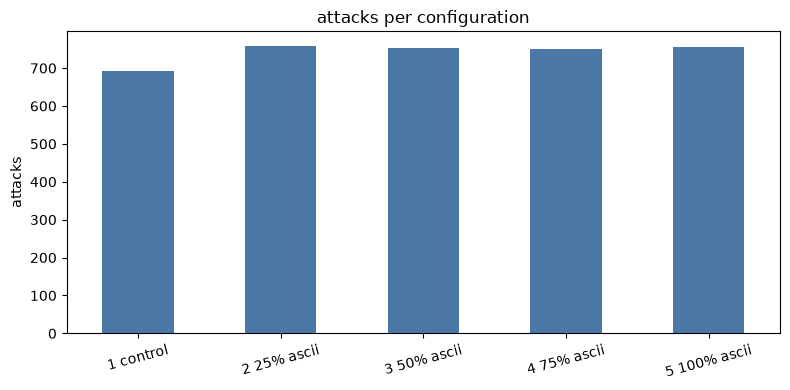

In [36]:
config_counts = df["config_label"].value_counts().reindex(ORDER)
config_share = (100 * config_counts / config_counts.sum()).round(1)
summary = pd.DataFrame({"attacks": config_counts, "percent": config_share})
display(summary)
spread = config_share.max() - config_share.min()
print(f"share spread: {spread:.1f} percentage points")
if spread <= 8:
    print("observation: the five configurations are close to an even split, so randomization is working.")
else:
    print("observation: the configurations are uneven. randomization may be off, or some honeypots were down.")

fig_config_counts, ax = plt.subplots(figsize=(8, 4))
summary["attacks"].plot(kind="bar", ax=ax, color="#4c78a8")
ax.set_title("attacks per configuration")
ax.set_xlabel("")
ax.set_ylabel("attacks")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


***
# Violin Plots

Please create the required plots listed below. Each plot should show individual observations and a violin with a box side by side for each configuration, all on the same graph. Please reference the examples in the modules on ELMS if you are unsure of what the plots are supposed to look like! You are welcome to add additional markdown/code blocks!

### **Required Plots**
You will need to make a plot for the following:
- Time spent per configuration
- Time spent (excluding timeouts) per configuration
- Time spent (unique IPs) per configuration
- Time spent (unique IPs, excluding timeouts) per configuration
- Number of commands per configuration
- Number of commands (unique IPs) per configuration

_You are welcome to make additional plots as you see fit. Incorrect/misleading plots may result in a penalty._

### **Documentation can be easily found online for additional functions!**
Suggestions:
- Start a new code block for each plot
- Use scatter and violin traces in one figure to show both the individual observations and their distribution for each configuration
- Give each plot a descriptive title
- Ensure that you are creating violin plots with boxes
  - You can use `box=True` as one of the arguments when making violin plots
- You can use `show()` to display the graph
  - Example: `fig.show()`

In [37]:
import plotly.graph_objects as go

# violin with a box, plus a companion scatter plot of individual observations
def make_violin(frame, y_col, title, y_label):
    plot_df = frame[frame["config_label"].isin(ORDER)].copy()
    colors = px.colors.qualitative.Plotly
    fig = go.Figure()
    for position, label in enumerate(ORDER):
        group = plot_df.loc[plot_df["config_label"] == label]
        if group.empty:
            continue
        color = colors[position % len(colors)]
        red, green, blue = px.colors.hex_to_rgb(color)
        jitter = [((index * 0.618033988749895) % 1 - 0.5) * 0.24 for index in range(len(group))]
        fig.add_trace(
            go.Scatter(
                x=[position + offset for offset in jitter],
                y=group[y_col],
                mode="markers",
                name=f"{label} observations",
                marker={"size": 5, "opacity": 1, "color": color},
                hovertemplate=f"{label}<br>{y_label}=%{{y}}<extra></extra>",
            )
        )
        fig.add_trace(
            go.Violin(
                x=[position + 0.55] * len(group),
                y=group[y_col],
                name=f"{label} distribution",
                width=0.42,
                box_visible=True,
                points=False,
                line_color=color,
                fillcolor=f"rgba({red}, {green}, {blue}, 0.25)",
                line_width=2,
                meanline_visible=False,
                hovertemplate=f"{label}<br>{y_label}=%{{y}}<extra></extra>",
            )
        )

    fig.update_layout(
        width=1300,
        height=520,
        title=title,
        showlegend=False,
        violingap=0,
        violinmode="overlay",
    )
    fig.update_xaxes(
        tickmode="array",
        tickvals=[position + 0.275 for position in range(len(ORDER))],
        ticktext=ORDER,
        range=[-0.35, len(ORDER) - 0.1],
        title_text="honeypot configuration",
        tickangle=-15,
    )
    fig.update_yaxes(title_text=y_label)
    fig.update_traces(spanmode="hard", selector={"type": "violin"})
    return fig, plot_df


def print_summary(plot_df, y_col, duration=False):
    rows = []
    for label in ORDER:
        group = plot_df.loc[plot_df["config_label"] == label, y_col]
        if group.empty:
            print(f"  {label}: n=0")
            continue
        median = float(group.median())
        row = {
            "configuration": label,
            "n": int(len(group)),
            "median": round(median, 1),
            "q1": round(float(group.quantile(0.25)), 1),
            "q3": round(float(group.quantile(0.75)), 1),
            "max": round(float(group.max()), 1),
        }
        rows.append(row)
        print(
            f"  {label}: n={row['n']} median={row['median']} "
            f"q1={row['q1']} q3={row['q3']} max={row['max']}"
        )
    summary = pd.DataFrame(rows)
    display(summary)
    if duration and len(rows) >= 2:
        spread = summary["median"].max() - summary["median"].min()
        print(f"median spread across configurations: {spread:.0f}s")
        if spread <= 15:
            print("observation: median durations are similar across configurations.")
        else:
            print("observation: median duration differs by configuration. compare the printed medians.")
    return summary


## Time spent per configuration

All attacks. A flat top at 300 seconds means the 5 minute kick is cutting sessions off.


In [38]:
fig_time_all, plot_time_all = make_violin(
    df.loc[df["session_seconds"] <= 250],
    "session_seconds",
    "time spent per configuration",
    "time spent (seconds)",
)
fig_time_all.show()
print_summary(plot_time_all, "session_seconds", duration=True)


  1 control: n=691 median=4.0 q1=2.0 q3=4.0 max=154.0
  2 25% ascii: n=759 median=4.0 q1=2.0 q3=4.0 max=168.0
  3 50% ascii: n=754 median=2.0 q1=2.0 q3=4.0 max=207.0
  4 75% ascii: n=750 median=2.0 q1=2.0 q3=4.0 max=218.0
  5 100% ascii: n=755 median=2.0 q1=2.0 q3=4.0 max=135.0


,configuration,n,median,q1,q3,max
0,1 control,691,4.0,2.0,4.0,154.0
1,2 25% ascii,759,4.0,2.0,4.0,168.0
2,3 50% ascii,754,2.0,2.0,4.0,207.0
3,4 75% ascii,750,2.0,2.0,4.0,218.0
4,5 100% ascii,755,2.0,2.0,4.0,135.0


median spread across configurations: 2s
observation: median durations are similar across configurations.


,configuration,n,median,q1,q3,max
0,1 control,691,4.0,2.0,4.0,154.0
1,2 25% ascii,759,4.0,2.0,4.0,168.0
2,3 50% ascii,754,2.0,2.0,4.0,207.0
3,4 75% ascii,750,2.0,2.0,4.0,218.0
4,5 100% ascii,755,2.0,2.0,4.0,135.0


## Time spent per configuration, excluding timeouts

Same plot after dropping sessions that reached the 5 minute limit. If the violins barely change, almost nobody was stopped by the time limit.


In [60]:
print(f"removed {int(df['hit_time_limit'].sum())} attacks that reached the time limit")
print(f"remaining attacks: {len(kept)}")
fig_time_all, plot_time_all = make_violin(
    df.loc[df["session_seconds"] <= 250].copy(),
    "session_seconds",
    "time spent per configuration",
    "time spent (seconds)",
)
fig_time_all.show()
print_summary(plot_time_all, "session_seconds", duration=True)

df.loc[df["session_seconds"] <= 250],

removed 0 attacks that reached the time limit
remaining attacks: 3710


  1 control: n=691 median=4.0 q1=2.0 q3=4.0 max=154.0
  2 25% ascii: n=759 median=4.0 q1=2.0 q3=4.0 max=168.0
  3 50% ascii: n=754 median=2.0 q1=2.0 q3=4.0 max=207.0
  4 75% ascii: n=750 median=2.0 q1=2.0 q3=4.0 max=218.0
  5 100% ascii: n=755 median=2.0 q1=2.0 q3=4.0 max=135.0


,configuration,n,median,q1,q3,max
0,1 control,691,4.0,2.0,4.0,154.0
1,2 25% ascii,759,4.0,2.0,4.0,168.0
2,3 50% ascii,754,2.0,2.0,4.0,207.0
3,4 75% ascii,750,2.0,2.0,4.0,218.0
4,5 100% ascii,755,2.0,2.0,4.0,135.0


median spread across configurations: 2s
observation: median durations are similar across configurations.


(               timestamp honeypot config      attacker_ip  session_seconds  \
 0    2026-10-28 19:52:20      hp1      3     179.43.153.2                2   
 1    2026-10-28 19:53:42      hp1      2     179.43.153.2                2   
 2    2026-10-28 19:55:01      hp1      3     179.43.153.2                2   
 3    2026-10-28 19:56:21      hp1      5     179.43.153.2                2   
 4    2026-10-28 19:57:40      hp1      4     179.43.153.2                2   
 ...                  ...      ...    ...              ...              ...   
 3705 2026-10-30 14:59:56      hp4      4     24.106.43.27                2   
 3706 2026-10-30 15:00:32      hp4      2    73.93.207.215                2   
 3707 2026-10-30 15:01:29      hp4      4      59.36.78.66               18   
 3708 2026-10-30 15:02:35      hp2      1  183.222.230.188               32   
 3709 2026-10-30 15:03:10      hp4      2    36.92.140.209                8   
 
              reason  commands  keystrokes  config

## Time spent per configuration, unique IPs

One row per IP: the earliest attack. Repeat visits from the same scanner no longer fill the violin.


In [61]:
print(f"unique ips: {len(first)} (from {len(known)} attacks with an ip)")
fig_time_unique, plot_time_unique = make_violin(
    first,
    "session_seconds",
    "time spent per configuration, unique ips",
    "time spent (seconds)",
)
fig_time_unique.show()
print_summary(plot_time_unique, "session_seconds", duration=True)


print("Sessions loaded:", len(df))
print("Sessions plotted:", len(plot_time_all))
print(plot_time_all.groupby("config_label").size())


unique ips: 64 (from 3710 attacks with an ip)


  1 control: n=14 median=6.0 q1=4.0 q3=8.8 max=68.0
  2 25% ascii: n=9 median=2.0 q1=2.0 q3=12.0 max=30.0
  3 50% ascii: n=12 median=5.0 q1=2.0 q3=7.0 max=73.0
  4 75% ascii: n=17 median=4.0 q1=2.0 q3=6.0 max=50.0
  5 100% ascii: n=12 median=4.0 q1=3.5 q3=7.5 max=26.0


,configuration,n,median,q1,q3,max
0,1 control,14,6.0,4.0,8.8,68.0
1,2 25% ascii,9,2.0,2.0,12.0,30.0
2,3 50% ascii,12,5.0,2.0,7.0,73.0
3,4 75% ascii,17,4.0,2.0,6.0,50.0
4,5 100% ascii,12,4.0,3.5,7.5,26.0


median spread across configurations: 4s
observation: median durations are similar across configurations.
Sessions loaded: 3710
Sessions plotted: 3709
config_label
1 control       691
2 25% ascii     759
3 50% ascii     754
4 75% ascii     750
5 100% ascii    755
dtype: int64


## Time spent per configuration, unique IPs, excluding timeouts

Same first-attack rows. IPs whose first attack reached the time limit are omitted.


In [62]:
print(f"removed {int(first['hit_time_limit'].sum())} first attacks that reached the time limit")
print(f"remaining unique ips: {len(first_kept)}")
fig_time_unique_no_timeout, plot_time_unique_no_timeout = make_violin(
    first_kept,
    "session_seconds",
    "time spent per configuration, unique ips, excluding timeouts",
    "time spent (seconds)",
)
fig_time_unique_no_timeout.show()
print_summary(plot_time_unique_no_timeout, "session_seconds", duration=True)


removed 0 first attacks that reached the time limit
remaining unique ips: 64


  1 control: n=14 median=6.0 q1=4.0 q3=8.8 max=68.0
  2 25% ascii: n=9 median=2.0 q1=2.0 q3=12.0 max=30.0
  3 50% ascii: n=12 median=5.0 q1=2.0 q3=7.0 max=73.0
  4 75% ascii: n=17 median=4.0 q1=2.0 q3=6.0 max=50.0
  5 100% ascii: n=12 median=4.0 q1=3.5 q3=7.5 max=26.0


,configuration,n,median,q1,q3,max
0,1 control,14,6.0,4.0,8.8,68.0
1,2 25% ascii,9,2.0,2.0,12.0,30.0
2,3 50% ascii,12,5.0,2.0,7.0,73.0
3,4 75% ascii,17,4.0,2.0,6.0,50.0
4,5 100% ascii,12,4.0,3.5,7.5,26.0


median spread across configurations: 4s
observation: median durations are similar across configurations.


,configuration,n,median,q1,q3,max
0,1 control,14,6.0,4.0,8.8,68.0
1,2 25% ascii,9,2.0,2.0,12.0,30.0
2,3 50% ascii,12,5.0,2.0,7.0,73.0
3,4 75% ascii,17,4.0,2.0,6.0,50.0
4,5 100% ascii,12,4.0,3.5,7.5,26.0


## Number of commands per configuration

Each attack contributes its `commands` count.


In [63]:
fig_commands, plot_commands = make_violin(
    df.dropna(subset=["commands"]),
    "commands",
    "number of commands per configuration",
    "number of commands",
)
fig_commands.show()
print_summary(plot_commands, "commands")


  1 control: n=691 median=1.0 q1=1.0 q3=1.0 max=15.0
  2 25% ascii: n=759 median=1.0 q1=1.0 q3=1.0 max=15.0
  3 50% ascii: n=754 median=1.0 q1=1.0 q3=1.0 max=15.0
  4 75% ascii: n=751 median=1.0 q1=1.0 q3=1.0 max=13.0
  5 100% ascii: n=755 median=1.0 q1=1.0 q3=1.0 max=13.0


,configuration,n,median,q1,q3,max
0,1 control,691,1.0,1.0,1.0,15.0
1,2 25% ascii,759,1.0,1.0,1.0,15.0
2,3 50% ascii,754,1.0,1.0,1.0,15.0
3,4 75% ascii,751,1.0,1.0,1.0,13.0
4,5 100% ascii,755,1.0,1.0,1.0,13.0


,configuration,n,median,q1,q3,max
0,1 control,691,1.0,1.0,1.0,15.0
1,2 25% ascii,759,1.0,1.0,1.0,15.0
2,3 50% ascii,754,1.0,1.0,1.0,15.0
3,4 75% ascii,751,1.0,1.0,1.0,13.0
4,5 100% ascii,755,1.0,1.0,1.0,13.0


## Number of commands per configuration, unique IPs

Same first-attack rows as the unique IP time plot. The command count is the count from that first attack.


In [64]:
print(f"unique ips: {len(first)}")
fig_commands_unique, plot_commands_unique = make_violin(
    first.dropna(subset=["commands"]),
    "commands",
    "number of commands per configuration, unique ips",
    "number of commands",
)
fig_commands_unique.show()
print_summary(plot_commands_unique, "commands")


unique ips: 64


  1 control: n=14 median=1.0 q1=1.0 q3=1.0 max=15.0
  2 25% ascii: n=9 median=1.0 q1=1.0 q3=1.0 max=1.0
  3 50% ascii: n=12 median=1.0 q1=0.8 q3=4.5 max=15.0
  4 75% ascii: n=17 median=1.0 q1=1.0 q3=1.0 max=6.0
  5 100% ascii: n=12 median=1.0 q1=1.0 q3=1.0 max=13.0


,configuration,n,median,q1,q3,max
0,1 control,14,1.0,1.0,1.0,15.0
1,2 25% ascii,9,1.0,1.0,1.0,1.0
2,3 50% ascii,12,1.0,0.8,4.5,15.0
3,4 75% ascii,17,1.0,1.0,1.0,6.0
4,5 100% ascii,12,1.0,1.0,1.0,13.0


,configuration,n,median,q1,q3,max
0,1 control,14,1.0,1.0,1.0,15.0
1,2 25% ascii,9,1.0,1.0,1.0,1.0
2,3 50% ascii,12,1.0,0.8,4.5,15.0
3,4 75% ascii,17,1.0,1.0,1.0,6.0
4,5 100% ascii,12,1.0,1.0,1.0,13.0


***
# Normality Tests

You are welcome to add additional markdown/code blocks!

### **Required Analyses**
You will need to conduct normality tests on the following:
- Time spent (excluding timeouts) per configuration
- Time spent (unique IPs, excluding timeouts) per configuration

_You are welcome to analyze additional data sets as you see fit. Incorrect/misleading analyses may result in a penalty._

### **Please use the following modules to perform the normality tests:**
Kolmogorov-Smirnov (KS) - use `kstest()` from `scipy.stats`
- If you did not modify the imports, the command should be `sp.stats.ktest(...)`

### **Remember that the documentation for all of these libraries and modules can be easily found online!**
Suggestions:
- Each test you conduct/dataset you investigate should be in its own code block
- Group tests together based on type (i.e. all ANOVA tests should be together, etc.)

## Kolmogorov-Smirnov tests

Each configuration is compared with `sp.stats.kstest` to a normal distribution that has that group's own mean and standard deviation. A group counts as normal when the p-value is at least 0.05. If any configuration fails, the later group comparison uses Kruskal-Wallis.

Group tests in the next section use 0.1 as the significance level, which is the cutoff named in the template.


In [65]:
def ks_table(frame, y_col, show=True):
    rows = []
    for label in ORDER:
        values = frame.loc[frame["config_label"] == label, y_col].dropna()
        n = int(len(values))
        std = float(values.std(ddof=1)) if n > 1 else 0.0
        if n < 3 or std == 0:
            rows.append({
                "configuration": label,
                "n": n,
                "ks_stat": None,
                "p_value": None,
                "normal_at_0.05": False,
            })
            continue
        stat, p = sp.stats.kstest(values, "norm", args=(float(values.mean()), std))
        rows.append({
            "configuration": label,
            "n": n,
            "ks_stat": round(float(stat), 4),
            "p_value": float(p),
            "normal_at_0.05": bool(p >= NORMAL_ALPHA),
        })
    table = pd.DataFrame(rows)
    if show:
        display(table)
    if bool(table["normal_at_0.05"].all()):
        print("every configuration is consistent with a normal distribution, so the group test is anova")
    else:
        print("at least one configuration is not normal, so the group test is kruskal-wallis")
    return table


### Time spent, excluding timeouts


In [66]:
ks_time_no_timeout = ks_table(kept, "session_seconds")


TypeError: ndtr() takes from 1 to 2 positional arguments but 3 were given

### Time spent, unique IPs, excluding timeouts


In [ ]:
ks_time_unique_no_timeout = ks_table(first_kept, "session_seconds")


### Number of commands

The command comparisons also need a normality check, so the same test is run here.


In [ ]:
ks_commands = ks_table(df.dropna(subset=["commands"]), "commands")


### Number of commands, unique IPs


In [ ]:
ks_commands_unique = ks_table(first.dropna(subset=["commands"]), "commands")


***
# Statistical Tests
You will need to conduct some statistical tests on your data. Consider refering to class slides and the statistics homework colab if you need a refresher on any of the tests. You are welcome to add additional markdown/code blocks!

### **Required Analyses**
You will need to conduct tests on the following:
- Time spent (excluding timeouts) per configuration
- Time spent (unique IPs, excluding timeouts) per configuration
- Number of commands per configuration
- Number of commands (unique IPs) per configuration

_You are welcome to analyze additional data sets as you see fit. Incorrect/misleading analyses may result in a penalty._

### **Please use the following modules to perform the statistical tests:**

ANOVA - use `anova_lm()` from `statsmodels.api.stats` (fancy ANOVA)
  - If you did not modify the imports, the command should be `sm.stats.anova_lm(...)`

TUKEY HSD - use `pairwise_tukeyhsd()`
  - You only need to run a Tukey HSD test if ANOVA is significant (p-value < 0.1)
  - Consider using an if statement!

KRUSKAL-WALLIS - use `kruskal()` from `scipy.stats`
  - If you did not modify the imports, the command should be `sp.stats.kruskal(...)`

DUNN - use `posthoc_dunn()` from `scikit_posthocs`
  - You only need to run a Dunn test if Kruskal-Wallis is significant (p-value < 0.1)
  - If you did not modify the imports, the command should be `spkh.posthoc_dunn(...)`

CHI SQUARED - use `chisquare()` from `scipy.stats`
- If you did not modify the imports, the command should be `sp.stats.chisquare(...)`
### **Remember that the documentation for all of these libraries and modules can be easily found online!**
Suggestions:
- Each test you conduct should be in its own code block
- Group tests together based on type (i.e. all ANOVA tests should be together, etc.)

## Group comparisons

ANOVA and Tukey HSD run when every configuration passed the normality check. Otherwise the comparison is Kruskal-Wallis, and Dunn's test runs when that p-value is below 0.1. Tukey and Dunn are skipped when the main test is not significant at 0.1.


In [ ]:
def run_group_test(frame, y_col):
    plot_df = frame[frame["config_label"].isin(ORDER)].dropna(subset=[y_col]).copy()
    table = ks_table(plot_df, y_col, show=False)
    labels = [label for label in ORDER if (plot_df["config_label"] == label).any()]
    samples = [plot_df.loc[plot_df["config_label"] == label, y_col] for label in labels]
    if bool(table["normal_at_0.05"].all()):
        model = ols(f"{y_col} ~ C(config_label)", data=plot_df).fit()
        anova = sm.stats.anova_lm(model, typ=2)
        display(anova)
        p = float(anova.loc["C(config_label)", "PR(>F)"])
        print(f"anova p-value: {p:.4g}")
        if p < SIGNIFICANCE:
            print(pairwise_tukeyhsd(plot_df[y_col], plot_df["config_label"], alpha=SIGNIFICANCE))
        else:
            print("anova p-value is at least 0.1, so tukey hsd is not run")
    else:
        result = sp.stats.kruskal(*samples)
        print(result)
        if result.pvalue < SIGNIFICANCE:
            dunn = skph.posthoc_dunn(
                plot_df,
                val_col=y_col,
                group_col="config_label",
                p_adjust="bonferroni",
            )
            display(dunn.reindex(index=labels, columns=labels))
        else:
            print("kruskal-wallis p-value is at least 0.1, so dunn is not run")
    return table


### Time spent, excluding timeouts


In [ ]:
test_time_no_timeout = run_group_test(kept, "session_seconds")


### Time spent, unique IPs, excluding timeouts


In [ ]:
test_time_unique_no_timeout = run_group_test(first_kept, "session_seconds")


### Number of commands

Medians are printed with the violin above. A significant Kruskal-Wallis result can still show up when those medians match, because the test ranks every attack, including the long upper tail.


In [ ]:
test_commands = run_group_test(df, "commands")


### Number of commands, unique IPs


In [ ]:
test_commands_unique = run_group_test(first, "commands")


### Attacks per configuration

Chi-square goodness of fit for an even share of attacks. This is the same question as the configuration count table above: did randomization give each honeypot about the same number of attacks?


In [ ]:
observed = df["config_label"].value_counts().reindex(ORDER)
chi_config = sp.stats.chisquare(observed)
display(observed.to_frame("attacks"))
print(chi_config)
if chi_config.pvalue < SIGNIFICANCE:
    print("the attack counts differ from an even split at the 0.1 level")
else:
    print("the attack counts are consistent with an even split at the 0.1 level")


***
# Additional Tests/Graphs
If your group would like to conduct additional statistical tests and/or generate more graphs, you are welcome to do so. Please note that you are responsible for producing accurate results. Any graphs and/or analysis results that are deemed incorrect may result in a penalty. You are welcome to add additional markdown/code blocks!